# A warm surface is not an air thermometer

**Objective:** Describe a measured surface-temperature distribution and distinguish its support from human heat exposure.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

The Landsat surface-temperature product estimates the emitting surface at the acquisition time. It is not the temperature of air at two metres, an indoor environment or a person. Landsat 9 thermal measurements have coarser native resolution (100 m) than the 30 m product grid. Resampling does not create 30 m independent thermal observations.

The table is systematically sampled again for this small browser package. A sample percentile describes this acquisition and this sampling scheme, not a daily maximum or a heat-health threshold.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=05_surface_heat.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
temperatures = sorted(values("temperature_c"))
def percentile(a, q):
    x = (len(a)-1)*q; i = int(x)
    return a[i] + (a[min(i+1, len(a)-1)]-a[i])*(x-i)
for q in (.05, .5, .95):
    print(f"Sample surface-temperature percentile {q:.0%}: {percentile(temperatures,q):.2f} °C")
assert all(-50 < t < 100 for t in temperatures)

Sample surface-temperature percentile 5%: 35.43 °C
Sample surface-temperature percentile 50%: 44.56 °C
Sample surface-temperature percentile 95%: 48.52 °C


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

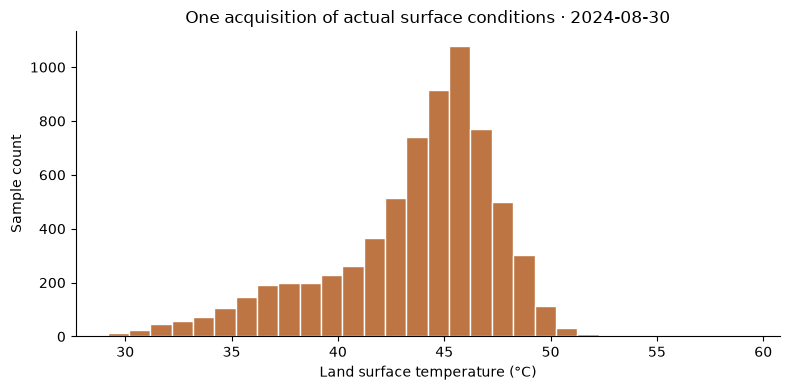

In [3]:
plt.hist(temperatures, bins=30, color="#be7544", edgecolor="white")
plt.xlabel("Land surface temperature (°C)"); plt.ylabel("Sample count")
plt.title("One acquisition of actual surface conditions · 2024-08-30")
plt.tight_layout(); plt.show()

## Interpret and extend

Write a short warning label for a map that could be mistaken for personal heat exposure. Then design a comparison with air-temperature stations, naming time alignment and station siting as requirements.

## Sources and attribution

- [USGS, Landsat Collection 2 surface temperature](https://www.usgs.gov/landsat-missions/landsat-collection-2-surface-temperature).
- [NASA, Landsat 9](https://science.nasa.gov/mission/landsat-9/).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.